# 06b · Optimización con seguimiento (tracking)

> Continúa `01b_caso_negocio_aprueba_o_no.ipynb` (**aprueba con 70 o más; con menos de 70 pierde el curso**; clase de interés `Fail`, 69,2 %; costos 5 : 1),
> `04b_features_aprueba_o_no.ipynb` (28 variables) y `05b_torneo_aprueba_o_no.ipynb` (**modelo ganador: regresión logística**, costo 0,2576 frente a 0,3079 de «avisar a todos»).
> Dataset: `data/student_exam_performance.csv`. Plantilla: `notebooks/06_optimizacion.ipynb`. Ejemplo de referencia: `material-del-curso/ejemplo-creditsight/notebooks/06_optimizacion.ipynb`.

Buscar mejores hiperparámetros es probar muchas configuraciones. Sin registro, a la mitad ya no sabes cuál era la buena. Aquí aparece el **tracking**: cada ensayo queda guardado en MLflow con sus parámetros, métricas y etiquetas, para poder **comparar, reproducir y auditar**.

Tres cuidados que separan una optimización seria de una ingenua:

1. **Se optimiza solo el modelo ganador del torneo** (la regresión logística), no todo el catálogo.
2. **El espacio de búsqueda es conocimiento, no azar**: la regresión logística casi no tiene hiperparámetros, así que el espacio es corto: `C` (cuánto se contienen los coeficientes) y el **umbral de decisión** (desde qué P(`Fail`) se avisa; la etapa 5 lo dejó en 0,167 *suponiendo* probabilidades bien calibradas, y aquí se ajusta con validación).
3. **La mejor puntuación de una búsqueda es optimista**: escoger el mejor de muchas pruebas sesga la estimación hacia arriba. Por eso se reservan estudiantes que la búsqueda **nunca ve** y se compara ahí contra los parámetros de partida, con un intervalo del 95 %.

**Diferencias con el ejemplo CreditSight.** Allí se optimizaban dos modelos (LightGBM y random forest) y el intervalo remuestreaba **clientes** porque cada uno tenía 8 meses. Aquí se optimiza **un solo modelo**, y como cada fila es un **estudiante distinto** (`student_id` único), el intervalo remuestrea **filas**. Además se busca el umbral, algo que allí no hacía falta.

**Regla de decisión (escrita ANTES de mirar la comprobación):** uso los parámetros optimizados **solo si todo el intervalo del 95 % de la diferencia de costo (optimizado − partida) queda por debajo de cero**. Si el intervalo cruza el cero, la mejora no se distingue del ruido y me quedo con los parámetros de partida (`C = 1`, umbral 0,167), que son más simples de explicar.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
# Permite importar tu paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

import json

import joblib
import matplotlib.pyplot as plt
import mlflow
import optuna

from proyecto.data.cleaning import TARGET
from proyecto.data.split import make_folds, split_train_test
from proyecto.features.engineering import STAGE4_ADD_MISSING_INDICATOR, STAGE4_DROP
from proyecto.models.train import (FALSE_NEGATIVE_COST, FALSE_POSITIVE_COST, build_pipeline, business_metrics,
                                   candidates, decision_threshold, encode_target, metrics_from_proba)
from proyecto.models.tuning import C_RANGE, MODELS, THRESHOLD_RANGE, bootstrap_cost_difference, tune
from proyecto.tracking.mlflow_utils import configure_mlflow, set_experiment

ROOT = Path.cwd().resolve().parent
SEED = 42
MODELO = "regresión logística"      # el ganador del torneo (reports/05_torneo.md)

## 1. Conexión con el seguimiento

Se usa el módulo del proyecto (`src/proyecto/tracking/mlflow_utils.py`) en modo **local**: en esta etapa no hace falta Databricks (entra en la etapa 8). Si prefieres probar Databricks, cambia `force_local=True` por `False` y define `.env` (ver `.env.example`); si no hay conexión, el módulo cae solo a local.

In [2]:
with warnings.catch_warnings(record=True) as avisos:   # mostramos por qué se usó (o no) Databricks
    warnings.simplefilter("always")
    donde = configure_mlflow(force_local=True)           # seguimiento local
for aviso in avisos:
    print("Aviso:", aviso.message)
experimento = set_experiment("proyecto-optimizacion-aprueba-o-no")
print("MLflow:", donde, "| experimento:", experimento)

2026/11/05 17:52:24 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/05 17:52:24 INFO mlflow.store.db.utils: Updating database tables


2026/11/05 17:52:28 INFO mlflow.tracking.fluent: Experiment with name 'proyecto-optimizacion-aprueba-o-no' does not exist. Creating a new experiment.


MLflow: local | experimento: proyecto-optimizacion-aprueba-o-no


> **En esta etapa el seguimiento es local:** todo se guarda en `mlflow_local.db` (raíz del repo, ignorado por Git).
> Para verlo en el navegador: `mlflow ui --backend-store-uri sqlite:///mlflow_local.db`.

## 2. Reservar estudiantes que la búsqueda no verá

Del conjunto de entrenamiento se separa el **25 % de los estudiantes** (estratificado por `pass_70`, semilla 7). La búsqueda trabaja solo con el 75 %; la **prueba final (`test.joblib`) sigue cerrada**. Se reserva **por fila** porque cada fila es un estudiante distinto (`student_id` único).

In [3]:
train_path = ROOT / "data" / "processed" / "train.joblib"
assert train_path.exists(), "Falta data/processed/train.joblib: ejecuta antes el notebook 03b_preprocesamiento_aprueba_o_no."
train = joblib.load(train_path)                              # SOLO entrenamiento: test.joblib NO se abre en esta etapa

busqueda, reservado = split_train_test(train, target=TARGET, test_size=0.25, seed=7)
X_busq, y_busq = busqueda.drop(columns=[TARGET]), encode_target(busqueda[TARGET])
X_res, y_res = reservado.drop(columns=[TARGET]), encode_target(reservado[TARGET])
folds = make_folds(busqueda[TARGET], n_splits=3, seed=SEED)  # validación cruzada DENTRO de la búsqueda

checks = {
    "ningún estudiante en los dos lados": set(busqueda.index).isdisjoint(set(reservado.index)),
    "no se perdió ninguna fila": len(busqueda) + len(reservado) == len(train) == 80_000,
    "los dos lados mantienen el ~69,2 % de Fail": abs(y_busq.mean() - y_res.mean()) < 0.005,
    "cada estudiante de la búsqueda se valida una sola vez": sorted(np.concatenate([v for _, v in folds])) == list(range(len(busqueda))),
}
result = pd.Series(checks, name="se cumple")
assert result.all(), result[~result]
display(result)
print(f"búsqueda: {len(busqueda):,} estudiantes (3 pliegues) · reservados: {len(reservado):,} · Fail = {y_busq.mean():.1%} / {y_res.mean():.1%} · la prueba sigue cerrada")

ningún estudiante en los dos lados                       True
no se perdió ninguna fila                                True
los dos lados mantienen el ~69,2 % de Fail               True
cada estudiante de la búsqueda se valida una sola vez    True
Name: se cumple, dtype: bool

búsqueda: 60,000 estudiantes (3 pliegues) · reservados: 20,000 · Fail = 69.2% / 69.2% · la prueba sigue cerrada


## 3. Espacio de búsqueda y presupuesto

Los rangos salen de lo que se sabe del algoritmo y el **presupuesto de ensayos se fija antes de empezar** (cada ensayo cuesta unos segundos; en Databricks Free Edition hay cuota diaria, así que no se gasta de más).

| Parámetro | Rango | Motivo |
|---|---|---|
| `C` (inversa de la regularización) | 0,001 a 100, escala **logarítmica** | `C = 1` es el valor de partida. Más chico contiene los coeficientes (útil con variables parecidas entre sí); más grande casi no regulariza. Los efectos se miden en órdenes de magnitud, por eso la escala logarítmica |
| `threshold` (umbral de decisión) | 0,05 a 0,40 | Alrededor del teórico 1 / (1 + 5) = 0,167. Más bajo avisa a más estudiantes; más alto, a menos. **No es del modelo sino de la decisión**: se ajusta aquí con validación, nunca con la prueba |

**Métrica que se optimiza:** el **costo esperado por estudiante** (la misma del torneo). No se optimiza solo el *recall*: empujaría a avisar a todos.

In [4]:
N_ENSAYOS = 25            # presupuesto fijado antes de empezar: el espacio tiene solo 2 parámetros
METRICA = "cost"          # la misma métrica principal del torneo (menor es mejor)

print(f"Modelo: {MODELO} · presupuesto: {N_ENSAYOS} ensayos · métrica: {METRICA}")
print(f"Rangos: C en {C_RANGE} (escala log) · umbral en {THRESHOLD_RANGE} (teórico: {decision_threshold():.3f})")

Modelo: regresión logística · presupuesto: 25 ensayos · métrica: cost
Rangos: C en (0.001, 100.0) (escala log) · umbral en (0.05, 0.4) (teórico: 0.167)


## 4. La búsqueda (un ensayo = una ejecución registrada)

Optuna usa un muestreador bayesiano (TPE): en vez de probar al azar, aprende qué zonas del espacio dieron mejor costo y explora más ahí. Cada ensayo es una **ejecución anidada** dentro de una ejecución madre en MLflow, con **todas** las métricas (negocio y técnicas) y su desviación entre pliegues.

In [5]:
estudio = tune(MODELO, X_busq, y_busq, folds, n_trials=N_ENSAYOS, seed=SEED, metric=METRICA)
mejor = estudio.best_trial
print(f"{MODELO}: mejor costo en la búsqueda = {estudio.best_value:.4f}  (ensayo {mejor.number} de {N_ENSAYOS})")
print(f"parámetros: C = {estudio.best_params['C']:.4g} · umbral = {estudio.best_params['threshold']:.3f}")

[I 2026-11-05 17:52:29,326] A new study created in memory with name: proyecto-regresión logística-cost


regresión logística: mejor costo en la búsqueda = 0.2582  (ensayo 19 de 25)
parámetros: C = 0.03757 · umbral = 0.167


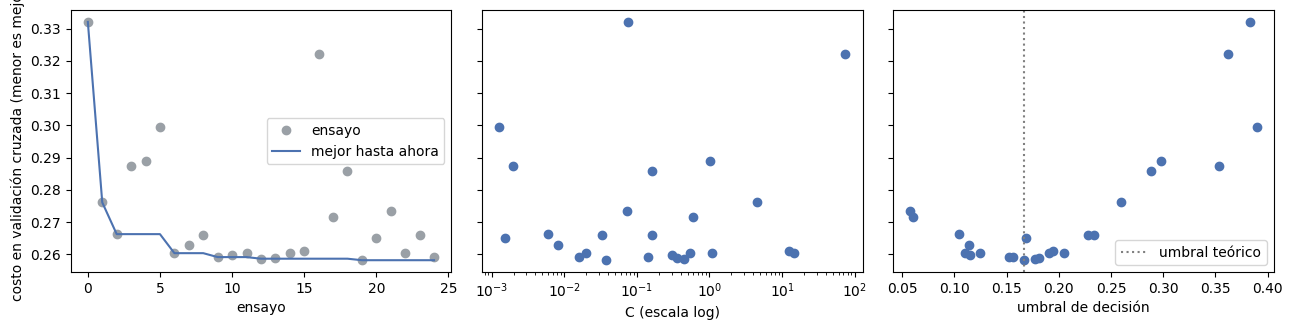

In [6]:
valores = [t.value for t in estudio.trials]
C_ens = [t.params["C"] for t in estudio.trials]
umbral_ens = [t.params["threshold"] for t in estudio.trials]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
axes[0].plot(valores, "o", color="#9aa0a6", label="ensayo")
axes[0].plot(np.minimum.accumulate(valores), "-", color="#4c72b0", label="mejor hasta ahora")
axes[0].set_xlabel("ensayo"); axes[0].legend(); axes[0].set_ylabel("costo en validación cruzada (menor es mejor)")
axes[1].scatter(C_ens, valores, color="#4c72b0"); axes[1].set_xscale("log"); axes[1].set_xlabel("C (escala log)")
axes[2].scatter(umbral_ens, valores, color="#4c72b0"); axes[2].axvline(decision_threshold(), color="grey", linestyle=":", label="umbral teórico")
axes[2].set_xlabel("umbral de decisión"); axes[2].legend()
plt.tight_layout(); plt.show()

## 5. ¿Qué parámetros importaron?

La importancia de cada parámetro dice dónde vale la pena seguir buscando y dónde no.

In [7]:
importancia = pd.Series(optuna.importance.get_param_importances(estudio), name="importancia").round(3)
display(importancia.to_frame())

,importancia
threshold,0.946
C,0.054


## 6. La comprobación honesta

Se comparan, sobre los **estudiantes reservados**, el modelo con parámetros de **partida** (`C = 1`, umbral 0,167: los del torneo) contra el modelo con los **mejores parámetros encontrados**. Ambos se entrenan con los mismos datos de la búsqueda y se evalúan en estudiantes que ninguno vio. La diferencia de costo lleva un **intervalo del 95 %**, remuestreando estudiantes.

In [8]:
partida_modelo, _ = candidates(SEED)[MODELO]
PARTIDA = {"C": float(partida_modelo.C), "threshold": decision_threshold()}      # parámetros del torneo
OPTIMIZADOS = dict(estudio.best_params)

_, make_fn, scale = MODELS[MODELO]
OPCIONES = dict(drop=STAGE4_DROP, add_missing_indicator=STAGE4_ADD_MISSING_INDICATOR, scale=scale)
modelo_partida = build_pipeline(partida_modelo, **OPCIONES).fit(X_busq, y_busq)
modelo_opt = build_pipeline(make_fn(OPTIMIZADOS), **OPCIONES).fit(X_busq, y_busq)
p_partida, p_opt = modelo_partida.predict_proba(X_res)[:, 1], modelo_opt.predict_proba(X_res)[:, 1]

m_partida = metrics_from_proba(y_res, p_partida, PARTIDA["threshold"])
m_opt = metrics_from_proba(y_res, p_opt, OPTIMIZADOS["threshold"])
diferencia, bajo, alto = bootstrap_cost_difference(y_res, p_opt, p_partida, OPTIMIZADOS["threshold"], PARTIDA["threshold"], n_boot=1000, seed=SEED)
costo_todos = business_metrics(y_res, np.ones(len(y_res), dtype=bool))["cost"]

comprobacion = pd.DataFrame({
    "partida": {"C": PARTIDA["C"], "umbral": PARTIDA["threshold"], "costo": m_partida["cost"], "log loss": m_partida["log_loss"],
                "ROC-AUC": m_partida["roc_auc"], "recall Fail": m_partida["recall_fail"], "NPV": m_partida["npv"],
                "alertas por 100": m_partida["alerts_per_100"]},
    "optimizado": {"C": OPTIMIZADOS["C"], "umbral": OPTIMIZADOS["threshold"], "costo": m_opt["cost"], "log loss": m_opt["log_loss"],
                   "ROC-AUC": m_opt["roc_auc"], "recall Fail": m_opt["recall_fail"], "NPV": m_opt["npv"],
                   "alertas por 100": m_opt["alerts_per_100"]},
})
display(comprobacion.round(4))
veredicto = "sí" if alto < 0 else ("no distinguible" if bajo <= 0 <= alto else "empeora")
print(f"Diferencia de costo (optimizado − partida) en {len(reservado):,} estudiantes reservados: {diferencia:+.5f}   IC 95 %: [{bajo:+.5f}, {alto:+.5f}]   ¿mejora real? {veredicto}")
print(f"Referencia: «avisar a todos» cuesta {costo_todos:.4f} en estos mismos estudiantes. Costo en la búsqueda (optimista): {estudio.best_value:.4f}")

,partida,optimizado
C,1.0000,0.0376
umbral,0.1667,0.1666
costo,0.2547,0.2548
log loss,0.3737,0.3736
ROC-AUC,0.8917,0.8918
recall Fail,0.9888,0.9893
NPV,0.9222,0.9241
alertas por 100,90.0350,90.2550


Diferencia de costo (optimizado − partida) en 20,000 estudiantes reservados: +0.00010   IC 95 %: [-0.00135, +0.00135]   ¿mejora real? no distinguible
Referencia: «avisar a todos» cuesta 0.3079 en estos mismos estudiantes. Costo en la búsqueda (optimista): 0.2582


**Cómo leer el intervalo:** si todo el intervalo está por debajo de cero, el modelo optimizado cuesta menos con confianza del 95 %. Si el intervalo cruza el cero, la mejora **no se distingue del ruido** en estos estudiantes: no hay evidencia de que optimizar sirvió, aunque el número haya bajado.

### Lo que muestran los números

- **Optimizar no mejoró nada medible.** En los 20.000 estudiantes reservados el modelo de partida cuesta 0,2547 y el optimizado 0,2548; la diferencia (+0,0001) tiene un intervalo del 95 % de ±0,0013 que **cruza el cero**. Siguiendo la regla escrita antes de mirar, **se quedan los parámetros de partida** (`C = 1`, umbral 0,167).
- **El umbral que encontró la búsqueda es el teórico.** Los mejores ensayos caen en un umbral de 0,167 ± 0,015, que es justo 1 / (1 + 5). Es buena noticia: significa que las probabilidades de la regresión logística están **razonablemente calibradas** para los costos 5 : 1 (la calibración formal se evalúa en la etapa 7). Ajustar el umbral con datos no aportó nada que la fórmula no diera.
- **`C` es casi irrelevante.** Los 5 mejores ensayos tienen `C` entre 0,016 y 0,44 y costos entre 0,2582 y 0,2592, una diferencia menor que el ruido entre pliegues (≈ 0,002). La importancia del umbral en la búsqueda (0,95) solo dice que el umbral movió el costo cuando se alejaba de 0,167; no que haya que cambiarlo.
- **La mejor puntuación de la búsqueda es optimista, y aquí también se nota qué comparar:** 0,2582 (búsqueda, validación cruzada con 60.000 estudiantes) y 0,2547 (reservados) no son comparables entre sí, porque son estudiantes distintos; diferencias de ± 0,003 entre subconjuntos son normales (el ruido entre pliegues del torneo fue de 0,003). Lo que sí es comparable es **partida frente a optimizado en los mismos estudiantes reservados**: empate.
- **Ahorro real, sin sesgo de optimización:** en los reservados, «avisar a todos» cuesta 0,3079 y el modelo 0,2547: **ahorro de 0,053 por estudiante (≈ 17 %)**, y sigue avisando a ≈ 90 de cada 100.
- **Era de esperar:** la regresión logística casi no tiene hiperparámetros. Se optimizó porque el procedimiento (tracking, reserva, intervalo) es parte del método, y el resultado negativo es información: **el modelo del torneo ya estaba bien**.

> **Una optimización sin mejora no es un fracaso:** documenta que se buscó con un presupuesto y un espacio justificados y que no se encontró nada mejor que la partida. Lo que **sí** podría cambiar el umbral es que la institución defina otros costos o una capacidad de tutoría: con la fórmula, umbral = costo del falso positivo / (costo del falso positivo + costo del falso negativo).

## 7. Lo que quedó registrado

Cada ensayo está en MLflow. Así se ven los mejores, ordenados por costo:

In [9]:
runs = mlflow.search_runs(
    experiment_names=[experimento],
    filter_string="tags.etapa = '06_optimizacion' and metrics.cost > 0",
    order_by=["metrics.cost ASC"],
    max_results=5,
)
cols = [c for c in ["tags.modelo", "run_id", "params.C", "params.threshold", "metrics.cost", "metrics.cost_std", "metrics.log_loss", "metrics.fit_seconds"] if c in runs.columns]
display(runs[cols].round(4))
todos = mlflow.search_runs(experiment_names=[experimento], filter_string="tags.etapa = '06_optimizacion' and metrics.cost > 0")
print(f"ensayos registrados en MLflow: {len(todos)} de {N_ENSAYOS} (se muestran los 5 mejores) · ejecución madre: {estudio.user_attrs.get('mlflow_parent_run_id')}")
assert len(todos) == N_ENSAYOS, "cada ensayo debe quedar como una ejecución registrada"

,tags.modelo,run_id,params.C,params.threshold,metrics.cost,metrics.cost_std,metrics.log_loss,metrics.fit_seconds
0,regresión logística,65f020450b824a65b2dd5f848df75f68,0.03757060314666423,0.16664263996144713,0.2582,0.0018,0.3728,1.0811
1,regresión logística,4572f7e5e0164fc085e55563518e83ec,0.444530332995028,0.17704087994811119,0.2587,0.0014,0.3728,0.7341
2,regresión logística,fd5372568d7b489797bc3a25684665ac,0.3589353788638115,0.1806006360146351,0.2590,0.0008,0.3728,0.7388
3,regresión logística,ef8dc75f4efe44beb541265ee7b00ee7,0.015997042090749546,0.1561282982420834,0.2592,0.0027,0.3731,1.2801
4,regresión logística,c2f641259a5c41bfa8009637a1b27413,0.14445251022763064,0.15193019906931468,0.2592,0.0022,0.3728,1.1949


ensayos registrados en MLflow: 25 de 25 (se muestran los 5 mejores) · ejecución madre: f54da878a2c447fab7e1cf799a25bde7


## 8. Guardar la decisión

Se aplica la regla escrita al principio y se guardan los parámetros que se usarán **a partir de ahora** (`reports/06_best_params.json`) y la tabla de la comprobación (`reports/06_comprobacion.csv`).

In [10]:
usar_optimizados = bool(alto < 0)                          # regla escrita ANTES: todo el intervalo por debajo de cero
decision = OPTIMIZADOS if usar_optimizados else PARTIDA
registro = {
    "modelo": MODELO,
    "decision": "parámetros optimizados" if usar_optimizados else "parámetros de partida (la mejora no se distingue del ruido)",
    "parametros": {"C": float(decision["C"]), "threshold": float(decision["threshold"])},
    "optimizados": {k: float(v) for k, v in OPTIMIZADOS.items()},
    "partida": {k: float(v) for k, v in PARTIDA.items()},
    "costo_busqueda_optimista": float(estudio.best_value),
    "costo_reservados": {"partida": float(m_partida["cost"]), "optimizado": float(m_opt["cost"]), "avisar_a_todos": float(costo_todos)},
    "diferencia_costo": {"valor": float(diferencia), "intervalo_95": [float(bajo), float(alto)]},
    "ensayos": N_ENSAYOS,
    "mlflow_parent_run_id": estudio.user_attrs.get("mlflow_parent_run_id"),
    "tracking": donde,
}
(ROOT / "reports").mkdir(exist_ok=True)
(ROOT / "reports" / "06_best_params.json").write_text(json.dumps(registro, indent=2, ensure_ascii=False), encoding="utf-8")
comprobacion.round(5).to_csv(ROOT / "reports" / "06_comprobacion.csv")
print("Decisión:", registro["decision"])
print("Parámetros a usar:", registro["parametros"])
print("guardado: reports/06_best_params.json y reports/06_comprobacion.csv")

Decisión: parámetros de partida (la mejora no se distingue del ruido)
Parámetros a usar: {'C': 1.0, 'threshold': 0.16666666666666666}
guardado: reports/06_best_params.json y reports/06_comprobacion.csv


## 9. Las pruebas automáticas

Desde la raíz del repo: `pytest -q`. Las funciones de esta etapa (`src/proyecto/models/tuning.py`) tienen pruebas con casos de mano en `tests/test_tuning.py`: el espacio de búsqueda y sus rangos, que el estudio respete el presupuesto y se **reanude** desde disco, que cada ensayo quede en MLflow, y los intervalos (diferencia cero para el mismo modelo, detecta un modelo claramente mejor y usa el umbral de cada uno).

In [11]:
import subprocess

run = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "tests/test_tuning.py", "tests/test_train.py", "tests/test_features.py", "tests/test_split.py",
                      "-p", "no:cacheprovider"], cwd=ROOT, capture_output=True, text=True)
print((run.stdout or run.stderr).strip()[-600:])

..............................................................           [100%]
62 passed in 10.37s


## Entregable de esta etapa

- [ ] **Un ensayo = una ejecución registrada**, con parámetros, métrica y etiquetas (`mlflow ui` lo muestra).
- [ ] El **presupuesto** de ensayos (25) está escrito y se respetó.
- [ ] Hay **estudiantes reservados** que la búsqueda nunca vio y `test.joblib` no se abrió.
- [ ] La **comprobación** (intervalo del 95 % remuestreando estudiantes) está hecha y la regla de decisión estaba escrita antes.
- [ ] `reports/06_optimizacion.md` y `reports/06_best_params.json` completados.
- [ ] El grupo aprobó la decisión sobre los parámetros (y el umbral, con la institución: depende de los costos 5 : 1 y de su capacidad).

**Siguiente:** `07_validacion_interpretacion.ipynb`: abrir la prueba **una sola vez**, evaluar calibración y equidad por grupo, e interpretar el modelo.